# Outreach Prioritization: Which Facilities Need Attention Next Quarter?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/nhsn-dialysis-analytics/blob/main/notebooks/04_outreach_prioritization.ipynb)

**Portfolio project 4 of 5** | Role focus: Data Analyst I, NHSN Dialysis Event prevention and surveillance support

---
## The problem
Outreach staff can call a limited number of facilities each quarter. Given everything known at the end of a quarter, **who should
be on the call list for the next one?** This notebook builds, evaluates, explains, and audits models that rank facilities by their
chance of a **high event rate next quarter**.

## How this notebook relates to notebooks 01 to 03
| Notebook | Contribution here |
|---|---|
| 01 data quality | Same simulated world (same seed, identical data) and the validation rules. Only **validated** records feed the rates; validation history becomes a *feature* |
| 02 rate models | Standardized ratios (SIR) and the lesson that small facilities are noisy: a shrunken SIR is a feature, and the "noise ceiling" idea reappears |
| 03 collaborative evaluation | The prevention collaborative (started Jan 2024) is a known program: enrollment is a feature, and the model should learn it lowers risk |

## Data statement
**No PHI and no real NHSN data.** All data are simulated; rates are illustrative. A hidden "true" facility risk exists in the
simulator and is used **only for evaluation** (a ceiling and a fairness yardstick), never as a model input.

## What this notebook does
| Step | Method |
|---|---|
| 2 | Leakage-safe quarterly dataset: features at the end of quarter *q*, outcome in quarter *q+1* |
| 3 | Baselines and a **noise ceiling** (how well could anyone do?) |
| 4 | Models: **regularized logistic regression**, **gradient boosting**, **tabular neural network** (PyTorch MLP, embeddings, dropout) |
| 5 | **Rolling-origin temporal evaluation** with facility-level bootstrap confidence intervals and paired comparisons |
| 6 | **Calibration**, **decision-curve analysis**, and **top-K outreach lists** |
| 7 | **Explainability**: SHAP, partial dependence, coefficients, permutation importance, plain-language reason codes |
| 8 | **Fairness audit** by facility size, ownership, and rural/urban, including a check against true risk |
| 9 | A **negative-control target** (data-quality errors that are random by construction) |
| 10 | The actual outreach list for the *next* (unobserved) quarter |

## 0. Setup

In [1]:
import sys, subprocess, importlib, warnings, os
warnings.filterwarnings("ignore")

def _ensure(pip_name, import_name=None):
    """Install a package only if it is missing (Colab already has most of these)."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, imp in [("numpy", None), ("pandas", None), ("scipy", None), ("matplotlib", None), ("scikit-learn", "sklearn"),
                      ("statsmodels", None), ("openpyxl", None), ("torch", None), ("shap", None)]:
    _ensure(pip_name, imp)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import torch
import torch.nn as nn
import shap
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve, precision_recall_curve
from sklearn.inspection import PartialDependenceDisplay
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)        # used ONLY by the notebook 01 recap, so the data match exactly
np.random.seed(SEED)
torch.manual_seed(SEED)
rng2 = np.random.default_rng(SEED + 1)   # separate stream for bootstraps

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
OUT = "outputs_04"
os.makedirs(OUT, exist_ok=True)
print("pandas", pd.__version__, "| torch", torch.__version__, "| shap", shap.__version__)

pandas 3.0.2 | torch 2.14.1+cu130 | shap 0.54.1


## 1. Rebuild the notebook 01 world
Compact copy of notebook 01 (configuration, generator, error injection, validation rules), collapsed in Colab.
**Do not change the seed or the order.** In a real repository these functions would live in `src/`.

In [2]:
#@title Recap from notebook 01: config { display-mode: "form" }
N_FACILITIES = 160
MONTHS = pd.period_range("2023-01", "2024-12", freq="M")      # 24 reporting months
ACCESS = ["AVF", "AVG", "CVC_tunneled", "CVC_nontunneled", "Other"]
EVENT_TYPES = ["positive_blood_culture", "iv_antimicrobial_start", "pus_redness_swelling"]

# Illustrative baseline rates per 100 patient-months, by access type (columns follow EVENT_TYPES order).
BASE_RATE = {
    "AVF":             [0.15, 0.45, 0.10],
    "AVG":             [0.35, 0.90, 0.25],
    "CVC_tunneled":    [1.10, 2.00, 0.40],
    "CVC_nontunneled": [2.50, 3.50, 0.80],
    "Other":           [0.30, 0.80, 0.20],
}

LATE_DAYS = 30           # submission later than this many days after month end counts as late
DUP_WINDOW_DAYS = 21     # same patient + same event type within this window = duplicate (illustrative rule)
MIN_PLAUSIBLE_YEAR = 2015

# Probability each record is hit by an injected error (facility-month level, then event level).
ERR_RATES = dict(
    missing=0.020, patient_typo=0.015, sum_mismatch=0.020, zero_access=0.030, late=0.030, inflation=0.025,
    duplicate=0.020, date_outside=0.015, date_implausible=0.007, access_swapped=0.015,
)
print(f"{N_FACILITIES} facilities x {len(MONTHS)} months = {N_FACILITIES*len(MONTHS):,} facility-months")

160 facilities x 24 months = 3,840 facility-months


In [3]:
#@title Recap from notebook 01: generator { display-mode: "form" }
def make_facilities(n, rng):
    states = ["FL", "GA", "TX", "CA", "NY", "OH", "PA", "IL", "NC", "MI"]
    state_network = {s: f"NW-{(i % 6) + 1:02d}" for i, s in enumerate(states)}   # synthetic network codes
    fac = pd.DataFrame({"facility_id": [f"FAC{i+1:04d}" for i in range(n)]})
    fac["state"] = rng.choice(states, n)
    fac["network"] = fac["state"].map(state_network)
    fac["ownership"] = rng.choice(["Large_chain", "Nonprofit", "Independent"], n, p=[0.60, 0.25, 0.15])
    fac["urban_rural"] = rng.choice(["Urban", "Rural"], n, p=[0.78, 0.22])
    size = rng.lognormal(np.log(65), 0.45, n) * np.where(fac["urban_rural"] == "Rural", 0.7, 1.0)
    fac["mean_census"] = np.clip(size, 15, 250).round().astype(int)
    base_mix = np.array([0.62, 0.13, 0.17, 0.02, 0.06])
    mix = np.vstack([rng.dirichlet(base_mix * 60) for _ in range(n)])
    for j, a in enumerate(ACCESS):
        fac[f"mix_{a}"] = mix[:, j]
    fac["log_effect"] = rng.normal(0, 0.35, n)             # latent facility risk (ground truth, never used as a feature)
    fac["in_collaborative"] = rng.random(n) < 0.40
    return fac


def make_clean_denominator(fac, months, rng):
    rows, mix_cols = [], [f"mix_{a}" for a in ACCESS]
    for f in fac.itertuples(index=False):
        mix = np.array([getattr(f, c) for c in mix_cols]); mix = mix / mix.sum()
        drift = rng.normal(0.002, 0.003)                    # slow census growth/decline
        for t, m in enumerate(months):
            start = m.to_timestamp()
            end = (m + 1).to_timestamp() - pd.Timedelta(days=1)
            total = max(8, int(round(f.mean_census * (1 + drift * t) * (1 + rng.normal(0, 0.025)))))
            counts = rng.multinomial(total, mix)
            delay = int(np.clip(rng.gamma(2.0, 5.0), 3, 28))   # typical on-time submission
            rows.append({"facility_id": f.facility_id, "month": start,
                         "report_date": end + pd.Timedelta(days=delay), "patients_total": total,
                         **{f"n_{a}": int(c) for a, c in zip(ACCESS, counts)}})
    return pd.DataFrame(rows)


def make_clean_events(fac, den, rng):
    info = fac.set_index("facility_id")[["log_effect", "in_collaborative", "mean_census"]].to_dict("index")
    collab_start, rows = pd.Timestamp("2024-01-01"), []
    for r in den.itertuples(index=False):
        f = info[r.facility_id]
        ndays = r.month.days_in_month
        post = bool(f["in_collaborative"]) and r.month >= collab_start
        shock = rng.gamma(20, 1 / 20)                         # monthly extra-Poisson variation
        pool = int(f["mean_census"] * 1.6)
        for a in ACCESS:
            n_a = getattr(r, f"n_{a}")
            if n_a == 0:
                continue
            mult = 0.7 if (post and a.startswith("CVC")) else 1.0
            for k, et in enumerate(EVENT_TYPES):
                lam = n_a * BASE_RATE[a][k] / 100 * np.exp(f["log_effect"]) * shock * mult
                for _ in range(rng.poisson(lam)):
                    rows.append({"facility_id": r.facility_id, "month": r.month,
                                 "patient_id": f"{r.facility_id}-P{rng.integers(1, pool + 1):04d}",
                                 "event_type": et, "access_type": a,
                                 "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, ndays)))})
    return pd.DataFrame(rows)


def enforce_dup_window(ev, window=DUP_WINDOW_DAYS):
    """Clean data should already obey the duplicate-event rule: drop a repeat for the same patient/type inside the window."""
    ev = ev.sort_values(["facility_id", "patient_id", "event_type", "event_date"]).reset_index(drop=True)
    keep, last_key, last_date = np.ones(len(ev), bool), None, None
    for i, (fid, pid, et, d) in enumerate(zip(ev.facility_id, ev.patient_id, ev.event_type, ev.event_date)):
        key = (fid, pid, et)
        if key == last_key and (d - last_date).days <= window:
            keep[i] = False
            continue
        last_key, last_date = key, d
    return ev[keep].reset_index(drop=True)


fac = make_facilities(N_FACILITIES, rng)
den_clean = make_clean_denominator(fac, MONTHS, rng)
ev_clean = enforce_dup_window(make_clean_events(fac, den_clean, rng))
ev_clean = ev_clean.sort_values(["facility_id", "month", "event_date"]).reset_index(drop=True)
ev_clean.insert(0, "event_id", [f"EV{i+1:06d}" for i in range(len(ev_clean))])

In [4]:
#@title Recap from notebook 01: error injection { display-mode: "form" }
def _append_label(ev, mask, label):
    cur = ev.loc[mask, "err_event"]
    ev.loc[mask, "err_event"] = np.where(cur == "", label, cur + "|" + label)


def inject_errors(den_c, ev_c, rng, rates=ERR_RATES):
    den, ev = den_c.copy(), ev_c.copy()
    n = len(den)
    cnt_cols = [f"n_{a}" for a in ACCESS]
    month_end = den["month"] + pd.offsets.MonthEnd(0)

    T = pd.DataFrame({"facility_id": den.facility_id, "month": den.month})
    for k in ["missing", "patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]:
        T[k] = rng.random(n) < rates[k]

    # --- facility-month errors on the denominator ---
    m = T.patient_typo.to_numpy()
    den.loc[m, ["patients_total"] + cnt_cols] = den.loc[m, ["patients_total"] + cnt_cols] * 10

    m = T.sum_mismatch.to_numpy()
    factor = 1 + rng.choice([-1, 1], m.sum()) * rng.uniform(0.08, 0.20, m.sum())
    den.loc[m, "patients_total"] = (den.loc[m, "patients_total"] * factor).round().astype(int)

    ev_by_key = ev_c.groupby(["facility_id", "month"])["access_type"].apply(list).to_dict()
    za_map = {}
    for i in np.flatnonzero(T.zero_access.to_numpy()):
        key = (den.at[i, "facility_id"], den.at[i, "month"])
        cands = sorted(a for a in set(ev_by_key.get(key, [])) if a != "AVF" and den_c.at[i, f"n_{a}"] > 0)   # sorted: set order varies between Python processes
        if not cands:
            T.at[i, "zero_access"] = False
            continue
        a = cands[int(rng.integers(len(cands)))]
        den.at[i, "n_AVF"] += den.at[i, f"n_{a}"]       # patients moved to AVF; total stays consistent
        den.at[i, f"n_{a}"] = 0
        za_map[key] = a

    m = T.late.to_numpy()
    den.loc[m, "report_date"] = month_end[m] + pd.to_timedelta(rng.integers(35, 91, m.sum()), unit="D")

    # --- event-level errors ---
    ev = ev.merge(den[["facility_id", "month", "report_date"]], on=["facility_id", "month"], how="left")
    ev["err_event"] = ""
    N = len(ev)
    k_out, k_imp, k_swap = (int(N * rates[x]) for x in ("date_outside", "date_implausible", "access_swapped"))
    perm = rng.permutation(N)
    i_out, i_imp = perm[:k_out], perm[k_out:k_out + k_imp]
    i_swap = perm[k_out + k_imp:k_out + k_imp + k_swap]
    i_dup = rng.choice(perm[k_out + k_imp + k_swap:], int(N * rates["duplicate"]), replace=False)

    shift = (rng.choice([-1, 1], k_out) * rng.integers(35, 70, k_out))
    ev.loc[i_out, "event_date"] = ev.loc[i_out, "event_date"].to_numpy() + pd.to_timedelta(shift, unit="D").to_numpy()
    half = len(i_imp) // 2
    ev.loc[i_imp[:half], "event_date"] = pd.Timestamp("1900-01-01")
    ev.loc[i_imp[half:], "event_date"] = ev.loc[i_imp[half:], "report_date"] + pd.Timedelta(days=180)
    ev.loc[i_swap, "access_type"] = [rng.choice([x for x in ACCESS if x != a]) for a in ev.loc[i_swap, "access_type"]]
    for idx, lab in [(i_out, "date_outside_month"), (i_imp, "date_implausible"), (i_swap, "access_swapped")]:
        ev.loc[idx, "err_event"] = lab

    dups = ev.loc[i_dup].copy()
    dups["event_id"] = "EVD" + dups["event_id"].str[2:]
    shifted = dups["event_date"] + pd.to_timedelta(rng.integers(1, 15, len(dups)), unit="D")
    dups["event_date"] = pd.concat([shifted, dups["month"] + pd.offsets.MonthEnd(0)], axis=1).min(axis=1)
    dups["err_event"] = "duplicate"

    # over-reporting: valid-looking extra events for new patient IDs, so no event-level rule can catch them
    extra, c = [], 0
    for i in np.flatnonzero(T.inflation.to_numpy()):
        r = den_c.iloc[i]
        w = np.array([r[f"n_{a}"] * sum(BASE_RATE[a]) for a in ACCESS], float)
        for _ in range(int(rng.integers(3, 8))):
            c += 1
            a = ACCESS[int(rng.choice(len(ACCESS), p=w / w.sum()))]
            extra.append({"event_id": f"EVX{c:06d}", "facility_id": r.facility_id, "month": r.month,
                          "patient_id": f"{r.facility_id}-X{c:05d}", "event_type": str(rng.choice(EVENT_TYPES)),
                          "access_type": a,
                          "event_date": r.month + pd.Timedelta(days=int(rng.integers(0, r.month.days_in_month))),
                          "report_date": den.at[i, "report_date"], "err_event": "inflated_valid"})
    ev = pd.concat([ev, dups, pd.DataFrame(extra)], ignore_index=True)

    # label events caused by facility-month problems, then apply missing denominators
    zero_flag = np.array([za_map.get((f, mo)) == a for f, mo, a in zip(ev.facility_id, ev.month, ev.access_type)])
    _append_label(ev, zero_flag, "den_zero_access")
    miss_keys = set(zip(T.loc[T.missing, "facility_id"], T.loc[T.missing, "month"]))
    _append_label(ev, np.array([k in miss_keys for k in zip(ev.facility_id, ev.month)]), "no_denominator")

    den_sub = den.loc[~T.missing.to_numpy()].reset_index(drop=True)
    truth_ev = ev[["event_id", "err_event"]].copy()
    ev_sub = ev.drop(columns="err_event").sort_values(["facility_id", "month", "event_id"]).reset_index(drop=True)
    T["has_fm_error"] = T[["patient_typo", "sum_mismatch", "zero_access", "late", "inflation"]].any(axis=1)
    return den_sub, ev_sub, truth_ev, T


den, ev, truth_ev, truth_fm = inject_errors(den_clean, ev_clean, rng)

In [5]:
#@title Recap from notebook 01: rule registry { display-mode: "form" }
RULES = pd.DataFrame([
    ("R1_date_outside_month", "event", 2, "Event date falls outside the reporting month it was entered under",
     "Hard stop at data entry when event date is outside the selected reporting month",
     "State that the event date, not the entry date, determines the reporting month."),
    ("R2_date_implausible", "event", 3, f"Event date before {MIN_PLAUSIBLE_YEAR} or after the submission date",
     "Block future dates and dates before facility enrollment",
     "Remind users that placeholder dates (for example 01/01/1900) must never be used."),
    ("R3_no_denominator", "event", 3, "Event reported for a facility-month with no submitted denominator",
     "Prevent saving events for a month until its denominator is submitted (or show a blocking alert)",
     "Add a step: complete the monthly denominator before entering events."),
    ("R4_zero_access_denominator", "event", 2, "Event access type has zero patients in that month's denominator",
     "Cross-field warning when event access type has a zero denominator count",
     "Clarify that denominator access-type counts must reflect each patient's access on the first two working days."),
    ("R5_duplicate_21d", "event", 2, f"Same patient and event type repeated within {DUP_WINDOW_DAYS} days",
     "Possible-duplicate alert that shows the earlier event at entry",
     "Add a worked example of the repeat-event window to the form instructions (confirm against current protocol)."),
    ("R6_missing_month", "facility-month", 2, "Enrolled facility has no denominator for a reporting month",
     "Automated missing-data report and reminder to facilities",
     "Add a monthly 'no events to report' attestation pathway."),
    ("R7_events_exceed_patients", "facility-month", 3, "Events for an access type exceed patients in that access category",
     "Numerator/denominator consistency check on submit",
     "Explain how event access type maps to denominator categories."),
    ("R8a_access_sum_mismatch", "facility-month", 2, "Total patients does not equal the sum of access-type counts",
     "Auto-calculate the total from access-type fields (read-only total)",
     "Clarify that the total is the sum of the access-type rows."),
    ("R8b_patient_count_outlier", "facility-month", 2, "Patient count is an outlier vs the facility's own history (robust |z| > 5)",
     "Soft warning when census differs sharply from prior months, with confirm button",
     "Add guidance for confirming unusually large or small census values."),
    ("R9_late_submission", "facility-month", 1, f"Submission more than {LATE_DAYS} days after month end",
     "Timeliness dashboard and automatic reminders at day 20 and day 28",
     "State the submission deadline prominently on the form."),
], columns=["rule_id", "level", "severity", "description", "proposed_modification", "form_instruction_edit"])

In [6]:
#@title Recap from notebook 01: validation functions { display-mode: "form" }
ACC_N = [f"n_{a}" for a in ACCESS]
EVENT_RULES = ["R1_date_outside_month", "R2_date_implausible", "R3_no_denominator", "R4_zero_access_denominator", "R5_duplicate_21d"]


def validate_events(ev, den):
    """Return the event line list with one boolean column per event-level rule."""
    e = ev.merge(den[["facility_id", "month"] + ACC_N], on=["facility_id", "month"], how="left", indicator=True)
    e["R3_no_denominator"] = e["_merge"].eq("left_only")
    a_idx = e["access_type"].map({a: i for i, a in enumerate(ACCESS)}).to_numpy()
    n_for_access = e[ACC_N].to_numpy(float)[np.arange(len(e)), a_idx]
    e["R4_zero_access_denominator"] = (~e["R3_no_denominator"]) & (np.nan_to_num(n_for_access, nan=1) == 0)
    e["R1_date_outside_month"] = e["event_date"].dt.to_period("M") != e["month"].dt.to_period("M")
    e["R2_date_implausible"] = (e["event_date"].dt.year < MIN_PLAUSIBLE_YEAR) | (e["event_date"] > e["report_date"])
    s = e.sort_values(["facility_id", "patient_id", "event_type", "event_date", "event_id"])
    same = (s[["facility_id", "patient_id", "event_type"]].shift().eq(s[["facility_id", "patient_id", "event_type"]]).all(axis=1))
    close = (s["event_date"] - s["event_date"].shift()).dt.days.between(0, DUP_WINDOW_DAYS)
    dup_ids = set(s.loc[same & close, "event_id"])
    e["R5_duplicate_21d"] = e["event_id"].isin(dup_ids)
    e["any_event_rule"] = e[EVENT_RULES].any(axis=1)
    return e.drop(columns=ACC_N + ["_merge"])


def validate_facility_months(den, ev_flags, months, fac_ids):
    grid = pd.MultiIndex.from_product([fac_ids, [m.to_timestamp() for m in months]],
                                      names=["facility_id", "month"]).to_frame(index=False)
    d = grid.merge(den, on=["facility_id", "month"], how="left")
    d["R6_missing_month"] = d["patients_total"].isna()
    present = ~d["R6_missing_month"]

    cnt = ev_flags.pivot_table(index=["facility_id", "month"], columns="access_type", values="event_id",
                               aggfunc="count", fill_value=0).reindex(columns=ACCESS, fill_value=0)
    cnt.columns = [f"ev_{a}" for a in ACCESS]
    d = d.merge(cnt.reset_index(), on=["facility_id", "month"], how="left")
    ev_cols = [f"ev_{a}" for a in ACCESS]
    d[ev_cols] = d[ev_cols].fillna(0).astype(int)
    d["events_total"] = d[ev_cols].sum(axis=1)

    d["R4_any"] = d.merge(ev_flags.groupby(["facility_id", "month"])["R4_zero_access_denominator"].any().rename("x").reset_index(),
                          on=["facility_id", "month"], how="left")["x"].fillna(False).astype(bool).to_numpy()
    d["R7_events_exceed_patients"] = present & (d[ev_cols].to_numpy() > d[ACC_N].fillna(0).to_numpy()).any(axis=1)
    d["R8a_access_sum_mismatch"] = present & (d["patients_total"] != d[ACC_N].sum(axis=1))
    lp = np.log(d["patients_total"].clip(lower=1))
    dev = lp - lp.groupby(d["facility_id"]).transform("median")
    mad = dev.abs().groupby(d["facility_id"]).transform("median")
    d["log_pat_dev"] = dev
    d["robust_z_patients"] = dev / np.maximum(1.4826 * mad, 0.03)       # floor avoids dividing by ~0
    d["R8b_patient_count_outlier"] = present & (d["robust_z_patients"].abs() > 5)
    d["delay_days"] = (d["report_date"] - (d["month"] + pd.offsets.MonthEnd(0))).dt.days
    d["R9_late_submission"] = present & (d["delay_days"] > LATE_DAYS)
    d["rule_fm_count"] = d[["R4_any", "R7_events_exceed_patients", "R8a_access_sum_mismatch",
                            "R8b_patient_count_outlier", "R9_late_submission"]].sum(axis=1)
    d["rule_fm_flag"] = d["rule_fm_count"] > 0
    return d


E = validate_events(ev, den)
D = validate_facility_months(den, E, MONTHS, fac.facility_id.tolist())

In [7]:
print(f"Recap done: {len(fac)} facilities, {len(den):,} denominator rows, {len(ev):,} submitted events; "
      f"{int(E.any_event_rule.sum())} events and {int(D.rule_fm_flag.sum())} facility-months flagged by the rules")

Recap done: 160 facilities, 3,758 denominator rows, 4,365 submitted events; 314 events and 314
    facility-months flagged by the rules


## 2. A leakage-safe quarterly dataset

**Timeline.** At the end of quarter *q* ("origin *q*") we know everything through quarter *q* and want to predict quarter *q+1*:

```
quarters:   Q1    Q2    Q3    Q4    Q5    Q6    Q7    Q8   | Q9 (unobserved)
origin 1:   [known]  -> predict Q2
origin 4:   [known........] -> predict Q5
origin 7:   [known.......................] -> predict Q8
origin 8:   [known.............................] -> predict Q9   <- the real outreach list
```

**Leakage controls** (the usual ways these models cheat):
- Every feature at origin *q* uses only data from quarters up to *q*.
- The **expected counts** behind every standardized ratio use access-specific rates estimated **only from quarters up to q**.
- Models are always trained on origins whose outcome quarter is already known at the prediction time (a model predicting from origin *q* is trained on origins before *q*).
- No random shuffling across time: evaluation moves forward through the calendar.

**Outcome ("high rate next quarter").** Observed events in quarter *q+1* are at least **1.5 times expected** *and* at least **3**
(the minimum avoids calling a facility "high" because of one extra event on a tiny expectation). Facilities with under 1 expected event in the outcome
quarter (for example, months removed by validation) are not scored.

**Features** (all known at the origin): recent and cumulative event counts and standardized ratios (also a shrunken ratio), trend and volatility,
CVC-specific rates, access mix, census, validation history (flagged and missing months, delays, invalid events), enrollment in the collaborative,
and facility characteristics.

In [8]:
# --- validated facility-month x access table (same construction as notebooks 02 and 03) ---
bad_fm = D.R6_missing_month | D.rule_fm_flag
bad_keys = set(zip(D.loc[bad_fm, "facility_id"], D.loc[bad_fm, "month"]))
ev_ok = E[~E.any_event_rule & ~pd.Series(list(zip(E.facility_id, E.month))).isin(bad_keys).to_numpy()].copy()
d_ok = D[~bad_fm].copy()

long = d_ok[["facility_id", "month"] + ACC_N].melt(id_vars=["facility_id", "month"], var_name="access", value_name="pm")
long["access"] = long["access"].str.replace("n_", "", regex=False)
cnt = (ev_ok.groupby(["facility_id", "month", "access_type"]).size().rename("events").reset_index().rename(columns={"access_type": "access"}))
long = long.merge(cnt, on=["facility_id", "month", "access"], how="left").fillna({"events": 0})
quarter_of = lambda m: ((m.dt.year - 2023) * 12 + m.dt.month - 1) // 3 + 1
long["q"] = quarter_of(long["month"])

fac_ids = sorted(fac.facility_id)
F, NQ, NA = len(fac_ids), 8, len(ACCESS)
qa = (long.groupby(["facility_id", "q", "access"]).agg(pm=("pm", "sum"), events=("events", "sum"))
      .reindex(pd.MultiIndex.from_product([fac_ids, range(1, NQ + 1), ACCESS], names=["facility_id", "q", "access"]), fill_value=0))
PM = qa["pm"].to_numpy(float).reshape(F, NQ, NA)          # patient-months by facility, quarter, access
EV = qa["events"].to_numpy(float).reshape(F, NQ, NA)      # validated events
CVC_IDX = [ACCESS.index("CVC_tunneled"), ACCESS.index("CVC_nontunneled")]

# --- validation history by facility-quarter (known at the end of each quarter) ---
Dq = D.assign(q=quarter_of(D["month"]))
def fq(series): return series.unstack("q").reindex(index=fac_ids, columns=range(1, NQ + 1))
g = Dq.groupby(["facility_id", "q"])
DQ_MISSING = fq(g["R6_missing_month"].sum()).fillna(0).to_numpy(float)
DQ_FLAG = fq(g["rule_fm_flag"].sum()).fillna(0).to_numpy(float)
DELAY = fq(g["delay_days"].mean()); DELAY = DELAY.fillna(float(D["delay_days"].median())).to_numpy(float)
Eq = E.assign(q=quarter_of(E["month"]))
INVALID = fq(Eq.groupby(["facility_id", "q"])["any_event_rule"].mean()).fillna(0).to_numpy(float)
DQ_BAD = ((DQ_MISSING + DQ_FLAG) > 0).astype(int)        # "poor data quality" in a quarter (used as a negative-control target later)

fac_i = fac.set_index("facility_id").loc[fac_ids]
OUTCOME_RATIO, OUTCOME_MIN_EVENTS, MIN_EXPECTED = 1.5, 3, 1.0

NUM = ["log_census", "cvc_share", "avf_share", "events_last_q", "events_last_2q", "events_cum", "exposure_last_q",
       "sir_last_q", "sir_last_2q", "sir_last_4q", "sir_cum", "sir_cum_shrunk", "sir_trend", "sir_sd",
       "cvc_rate_last_q", "cvc_rate_cum", "cvc_events_cum", "dq_missing_last_q", "dq_flag_last_q", "dq_flag_cum",
       "delay_last_q", "invalid_share_last_q", "enrolled_next_q", "hist_quarters"]
CAT = ["ownership", "urban_rural", "network"]
COMPACT = ["sir_cum_shrunk", "sir_cum", "sir_last_4q", "cvc_rate_cum", "enrolled_next_q", "log_census"]   # a parsimonious, domain-driven subset


def rows_at(q, with_label=True):
    """Features at the end of quarter q (1-based); label = high rate in quarter q+1 (if observed)."""
    cur = q - 1
    rate = EV[:, :q, :].sum((0, 1)) / np.maximum(PM[:, :q, :].sum((0, 1)), 1e-9)      # access-specific rates, history only
    E_k = PM[:, :q, :] @ rate                                                          # expected events per quarter, history only
    O_k = EV[:, :q, :].sum(2)
    ratio = lambda o, e: np.where(e > 0.5, o / np.maximum(e, 1e-9), np.nan)
    sir_k = ratio(O_k, E_k)
    lo2, lo4 = max(0, cur - 1), max(0, cur - 3)
    sir_last_q = np.nan_to_num(sir_k[:, cur], nan=1.0)
    sir_prev = np.nan_to_num(sir_k[:, cur - 1], nan=1.0) if cur >= 1 else sir_last_q
    sir_sd = np.nan_to_num(np.nanstd(sir_k, axis=1), nan=0.0) if q >= 2 else np.zeros(F)
    pm_cur = PM[:, cur, :].sum(1)
    X = pd.DataFrame({
        "facility_id": fac_ids, "origin": q,
        "log_census": np.log(np.maximum(pm_cur / 3, 1)),
        "cvc_share": PM[:, cur, CVC_IDX].sum(1) / np.maximum(pm_cur, 1),
        "avf_share": PM[:, cur, 0] / np.maximum(pm_cur, 1),
        "events_last_q": O_k[:, cur], "events_last_2q": O_k[:, lo2:cur + 1].sum(1), "events_cum": O_k.sum(1),
        "exposure_last_q": E_k[:, cur],
        "sir_last_q": sir_last_q,
        "sir_last_2q": np.nan_to_num(ratio(O_k[:, lo2:cur + 1].sum(1), E_k[:, lo2:cur + 1].sum(1)), nan=1.0),
        "sir_last_4q": np.nan_to_num(ratio(O_k[:, lo4:cur + 1].sum(1), E_k[:, lo4:cur + 1].sum(1)), nan=1.0),
        "sir_cum": np.nan_to_num(ratio(O_k.sum(1), E_k.sum(1)), nan=1.0),
        "sir_cum_shrunk": (O_k.sum(1) + 5) / (E_k.sum(1) + 5),                          # credibility-weighted ratio (notebook 02 idea)
        "sir_trend": sir_last_q - sir_prev, "sir_sd": sir_sd,
        "cvc_rate_last_q": 100 * EV[:, cur, CVC_IDX].sum(1) / np.maximum(PM[:, cur, CVC_IDX].sum(1), 1),
        "cvc_rate_cum": 100 * EV[:, :q, :][:, :, CVC_IDX].sum((1, 2)) / np.maximum(PM[:, :q, :][:, :, CVC_IDX].sum((1, 2)), 1),
        "cvc_events_cum": EV[:, :q, :][:, :, CVC_IDX].sum((1, 2)),
        "dq_missing_last_q": DQ_MISSING[:, cur], "dq_flag_last_q": DQ_FLAG[:, cur], "dq_flag_cum": DQ_FLAG[:, :q].sum(1),
        "delay_last_q": DELAY[:, cur], "invalid_share_last_q": INVALID[:, cur],
        "enrolled_next_q": (fac_i["in_collaborative"].to_numpy() & (q + 1 >= 5)).astype(float),   # planned participation, known in advance
        "hist_quarters": float(q),
        "ownership": fac_i["ownership"].to_numpy(), "urban_rural": fac_i["urban_rural"].to_numpy(), "network": fac_i["network"].to_numpy(),
    })
    X["true_log_effect"] = fac_i["log_effect"].to_numpy()        # GROUND TRUTH: evaluation only, never a feature
    if with_label and q < NQ:
        e_next = PM[:, q, :] @ rate                              # expected next quarter using rates known at the origin
        o_next = EV[:, q, :].sum(1)
        X["y"] = ((o_next >= OUTCOME_RATIO * e_next) & (o_next >= OUTCOME_MIN_EVENTS)).astype(int)
        X["scored"] = e_next >= MIN_EXPECTED
        X["y_dq"] = DQ_BAD[:, q]                                 # next-quarter data-quality problem (negative-control target)
    return X

ds_all = pd.concat([rows_at(q) for q in range(1, NQ)], ignore_index=True)
n_before = len(ds_all)
ds = ds_all[ds_all.scored].drop(columns="scored").reset_index(drop=True)
mu_te = fac_i["log_effect"].mean()
ds["true_high"] = (np.exp(ds.true_log_effect - mu_te) >= 1.3).astype(int)      # GROUND TRUTH latent risk >= 1.3x average (evaluation only)
ds = ds.merge(fac[["facility_id", "mean_census"]], on="facility_id")
ds["size_group"] = ds.facility_id.map(pd.qcut(fac.set_index("facility_id").mean_census, 3, labels=["Small", "Medium", "Large"]))

print(f"Rows: {len(ds):,} facility-origins (dropped {n_before - len(ds)} with under {MIN_EXPECTED:.0f} expected events in the outcome quarter) | features: {len(NUM)} numeric + {len(CAT)} categorical")
prev = ds.groupby("origin").agg(rows=("y", "size"), high_next_q=("y", "sum"), prevalence=("y", "mean")).round(3)
display(prev)

Rows: 1,050 facility-origins (dropped 70 with under 1 expected events in the outcome quarter) |
    features: 24 numeric + 3 categorical


,rows,high_next_q,prevalence
origin,,,
1,151,50,0.331
2,149,31,0.208
3,146,31,0.212
4,151,25,0.166
5,153,26,0.170
6,149,39,0.262
7,151,26,0.172


## 3. Baselines and the noise ceiling
Before any model, three reference points:
- **Last-quarter ratio** (what a busy analyst might use) and **cumulative ratio** (all history): simple scores with no learning.
- **Noise ceiling (ground truth, simulation only):** the AUROC you would get by knowing each facility's *true* latent risk exactly.
  The outcome is a noisy count (about three events per quarter), so even perfect knowledge of risk cannot predict it perfectly.
  Any model near the ceiling is doing all that can be done; one far below it has room to improve.

,AUROC: last-quarter ratio,AUROC: cumulative ratio,AUROC: noise ceiling (true risk)
1,0.536,0.536,0.692
2,0.559,0.615,0.706
3,0.544,0.594,0.718
4,0.592,0.637,0.698
5,0.588,0.647,0.745
6,0.600,0.621,0.700
7,0.618,0.673,0.710


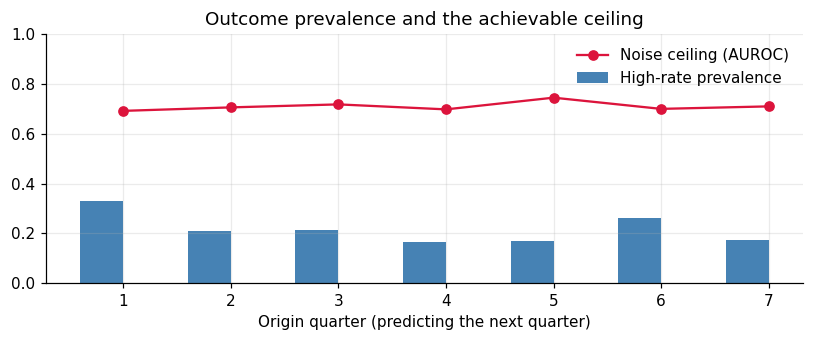

In [9]:
ceil = {o: roc_auc_score(g_.y, g_.true_log_effect) for o, g_ in ds.groupby("origin")}
base = pd.DataFrame({
    "AUROC: last-quarter ratio": {o: roc_auc_score(g_.y, g_.sir_last_q) for o, g_ in ds.groupby("origin")},
    "AUROC: cumulative ratio": {o: roc_auc_score(g_.y, g_.sir_cum) for o, g_ in ds.groupby("origin")},
    "AUROC: noise ceiling (true risk)": ceil,
}).round(3)
display(base)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(prev.index - 0.2, prev.prevalence, width=0.4, label="High-rate prevalence", color="steelblue")
ax.plot(base.index, base["AUROC: noise ceiling (true risk)"], "o-", color="crimson", label="Noise ceiling (AUROC)")
ax.set_xlabel("Origin quarter (predicting the next quarter)"); ax.set_ylim(0, 1); ax.legend(frameon=False)
ax.set_title("Outcome prevalence and the achievable ceiling")
plt.tight_layout(); plt.show()

## 4. The three models
**Protocol.** Hyperparameters, and the choice between the **full** feature set and a **compact** six-feature subset, are chosen **only on origins 1 to 4**
by *forward-chaining validation* (train on origins up to *k-1*, validate on origin *k*, for *k* = 3 and 4). The selection criterion is **mean log loss**,
a proper scoring rule that rewards honest probabilities (selecting on AUROC alone ignores calibration, and an early version of this notebook that did exactly that
produced badly overconfident boosting and neural-network probabilities). Origins 5 to 7 are then a **rolling-origin test**: for each test origin the
model is refit on all earlier origins and predicts the next one, exactly as it would run in production. No test origin ever influences model
selection.

- **Regularized logistic regression** (elastic-net family: ridge, or ridge-lasso mix), on standardized features. Simple, stable, explainable.
- **Gradient boosting** (shallow trees, subsampling) on raw-unit features, so SHAP and partial dependence read in natural units.
- **Tabular neural network (PyTorch):** embeddings for categorical variables, two hidden layers, dropout, weight decay, and an ensemble of 5 seeds.
  With about 600 to 900 training rows this is a small-data problem, where neural networks rarely beat simpler models. We test that, we do not assume it.
  Its number of training epochs (10, 25, or 60) is selected the same way as the other models' hyperparameters, since an over-trained network is overconfident.

In [10]:
LEVELS = [sorted(fac[c].unique()) for c in CAT]

def feature_cols(params):
    return NUM if params.get("features", "full") == "full" else COMPACT

def make_pre(kind, num_cols):
    cat = OneHotEncoder(handle_unknown="ignore", sparse_output=False, categories=LEVELS)
    num = StandardScaler() if kind == "scaled" else "passthrough"
    cat_cols = CAT if len(num_cols) == len(NUM) else []              # the compact set is numeric only
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)], verbose_feature_names_out=False).set_output(transform="pandas")

def fit_lr(tr, params, target="y"):
    pre = make_pre("scaled", feature_cols(params)); X = pre.fit_transform(tr)
    clf = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=params["l1_ratio"], C=params["C"], max_iter=5000, random_state=SEED)
    return pre, clf.fit(X, tr[target])

def fit_gb(tr, params, target="y"):
    pre = make_pre("raw", feature_cols(params)); X = pre.fit_transform(tr)
    gb_params = {k: v for k, v in params.items() if k != "features"}
    clf = GradientBoostingClassifier(learning_rate=0.05, subsample=0.8, min_samples_leaf=10, random_state=SEED, **gb_params)
    return pre, clf.fit(X, tr[target])

def predict_sk(obj, df):
    pre, clf = obj
    return clf.predict_proba(pre.transform(df))[:, 1]

class TabNet(nn.Module):
    def __init__(self, n_num, cards, emb_dim=3, hidden=(32, 16), p=0.3):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, min(emb_dim, c)) for c in cards])
        d = n_num + sum(min(emb_dim, c) for c in cards)
        self.mlp = nn.Sequential(nn.Linear(d, hidden[0]), nn.ReLU(), nn.Dropout(p), nn.Linear(hidden[0], hidden[1]), nn.ReLU(), nn.Dropout(p), nn.Linear(hidden[1], 1))
    def forward(self, xn, xc):
        return self.mlp(torch.cat([xn] + [e(xc[:, i]) for i, e in enumerate(self.embs)], dim=1)).squeeze(1)

def _nn_inputs(df, scaler):
    xn = np.clip(scaler.transform(df[NUM]), -5, 5).astype(np.float32)
    xc = np.stack([df[c].map({l: i for i, l in enumerate(lv)}).to_numpy() for c, lv in zip(CAT, LEVELS)], axis=1).astype(np.int64)
    return torch.from_numpy(xn), torch.from_numpy(xc)

NN_PARAMS = dict(epochs=60, lr=2e-3, weight_decay=1e-2, dropout=0.3, batch=64, seeds=5)

def fit_nn(tr, params=NN_PARAMS, target="y"):
    sc = StandardScaler().fit(tr[NUM]); xn, xc = _nn_inputs(tr, sc); yt = torch.from_numpy(tr[target].to_numpy(np.float32))
    nets = []
    for s in range(params["seeds"]):
        torch.manual_seed(SEED + s)
        net = TabNet(len(NUM), [len(l) for l in LEVELS], p=params["dropout"])
        opt = torch.optim.AdamW(net.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
        for ep in range(params["epochs"]):
            net.train(); perm = torch.randperm(len(yt))
            for i in range(0, len(yt), params["batch"]):
                b = perm[i:i + params["batch"]]
                loss = nn.functional.binary_cross_entropy_with_logits(net(xn[b], xc[b]), yt[b])
                opt.zero_grad(); loss.backward(); opt.step()
        nets.append(net.eval())
    return sc, nets

def predict_nn(obj, df):
    sc, nets = obj; xn, xc = _nn_inputs(df, sc)
    with torch.no_grad():
        return np.mean([torch.sigmoid(n(xn, xc)).numpy() for n in nets], axis=0)

# --- hyperparameter selection on origins 1-4 only (forward chaining), by mean log loss ---
dev = ds[ds.origin <= 4]
def forward_cv(fit, predict, params):
    aucs, lls = [], []
    for k in (3, 4):
        tr, va = dev[dev.origin < k], dev[dev.origin == k]
        p = np.clip(predict(fit(tr, params), va), 1e-4, 1 - 1e-4)
        aucs.append(roc_auc_score(va.y, p)); lls.append(log_loss(va.y, p))
    return float(np.mean(aucs)), float(np.mean(lls))

lr_grid = [dict(C=C, l1_ratio=r, features=fs) for fs in ("full", "compact") for C in (0.01, 0.03, 0.1, 0.3, 1.0) for r in (0.0, 0.5)]
gb_grid = [dict(max_depth=d, n_estimators=n, features=fs) for fs in ("full", "compact") for d in (1, 2) for n in (40, 100, 200)]
nn_grid = [dict(NN_PARAMS, epochs=e, seeds=3) for e in (10, 25, 60)]
def tune(grid, fit, predict):
    out = pd.DataFrame([{k: v for k, v in p.items() if k in ("C", "l1_ratio", "max_depth", "n_estimators", "features", "epochs")} for p in grid])
    res = [forward_cv(fit, predict, p) for p in grid]
    out["inner AUROC"], out["inner log loss"] = [r[0] for r in res], [r[1] for r in res]
    return grid[int(out["inner log loss"].idxmin())], out
best_lr, lr_cv = tune(lr_grid, fit_lr, predict_sk)
best_gb, gb_cv = tune(gb_grid, fit_gb, predict_sk)
best_nn, nn_cv = tune(nn_grid, fit_nn, predict_nn)
best_nn = dict(best_nn, seeds=5)
for name, cv_ in [("Logistic regression", lr_cv), ("Gradient boosting", gb_cv), ("Neural network (epochs)", nn_cv)]:
    print(name, "- best 3 by inner log loss:"); display(cv_.sort_values("inner log loss").head(3).round(3).reset_index(drop=True))
print("Selected (origins 1-4 only):", {"LR": best_lr, "GB": best_gb, "NN epochs": best_nn["epochs"]})

Logistic regression - best 3 by inner log loss:


,C,l1_ratio,features,inner AUROC,inner log loss
0,0.01,0.0,full,0.576,0.479
1,0.10,0.5,full,0.580,0.481
2,0.03,0.0,full,0.578,0.483


Gradient boosting - best 3 by inner log loss:


,max_depth,n_estimators,features,inner AUROC,inner log loss
0,1,200,compact,0.596,0.483
1,1,100,compact,0.598,0.484
2,1,100,full,0.579,0.485


Neural network (epochs) - best 3 by inner log loss:


,epochs,inner AUROC,inner log loss
0,10,0.556,0.484
1,25,0.568,0.507
2,60,0.577,0.625


Selected (origins 1-4 only): {'LR': {'C': 0.01, 'l1_ratio': 0.0, 'features': 'full'}, 'GB':
    {'max_depth': 1, 'n_estimators': 200, 'features': 'compact'}, 'NN epochs': 10}


## 5. Rolling-origin test with bootstrap confidence intervals
For each test origin (5, 6, 7) every model is refit on **all earlier origins** and predicts the next quarter. The three sets of out-of-time
predictions are pooled (about 450 facility-quarters). Because the same facility appears at several origins, confidence intervals come from a
**facility-level bootstrap** (resample whole facilities, 1,000 times). Model differences are **paired** (same resamples), so they show whether one model
is really better, not just whether the intervals overlap.

Pooled out-of-time test: 453 facility-quarters | prevalence 0.201 | origins (5, 6, 7)


,model,AUROC (95% CI),AUPRC (95% CI),Brier (95% CI)
0,Logistic regression,0.577 (0.516 to 0.643),0.289 (0.206 to 0.384),0.158 (0.131 to 0.185)
1,Gradient boosting,0.586 (0.526 to 0.652),0.247 (0.188 to 0.331),0.159 (0.135 to 0.185)
2,Neural network,0.564 (0.500 to 0.631),0.256 (0.191 to 0.336),0.161 (0.132 to 0.188)
3,Last-quarter ratio,0.594 (0.529 to 0.659),0.258 (0.192 to 0.344),n/a (not a probability)
4,Cumulative ratio,0.638 (0.575 to 0.702),0.284 (0.208 to 0.395),n/a (not a probability)


Prevalence (AUPRC of a random scorer): 0.201 | noise ceiling AUROC on this test set (true risk,
    simulation only): 0.715


,comparison,dAUROC (95% CI),dAUPRC (95% CI),AUROC interval excludes 0?
0,Gradient boosting minus Logistic regression,+0.008 (-0.037 to +0.056),-0.040 (-0.082 to +0.001),False
1,Neural network minus Logistic regression,-0.014 (-0.046 to +0.016),-0.033 (-0.072 to +0.004),False
2,Neural network minus Gradient boosting,-0.022 (-0.076 to +0.031),+0.008 (-0.031 to +0.051),False
3,Logistic regression minus Cumulative ratio,-0.060 (-0.105 to -0.016),+0.001 (-0.041 to +0.040),True
4,Gradient boosting minus Cumulative ratio,-0.053 (-0.091 to -0.011),-0.039 (-0.087 to -0.003),True


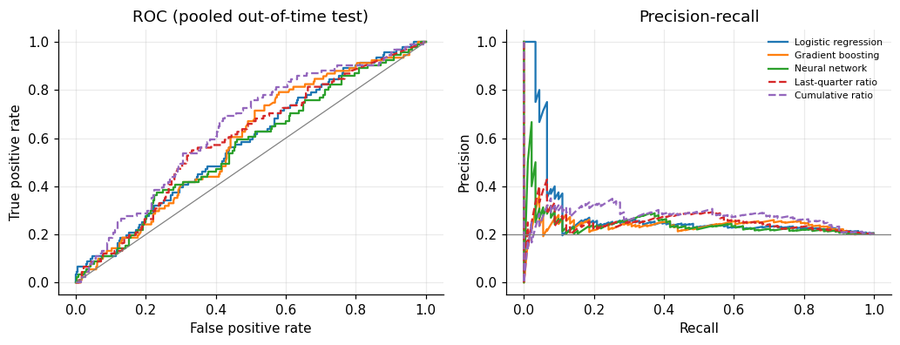

In [11]:
TEST_ORIGINS = (5, 6, 7)
fits_at = {}
parts = []
for q in TEST_ORIGINS:
    tr, te = ds[ds.origin < q], ds[ds.origin == q].copy()
    f_lr, f_gb, f_nn = fit_lr(tr, best_lr), fit_gb(tr, best_gb), fit_nn(tr, best_nn)
    fits_at[q] = (f_lr, f_gb, f_nn)
    te["p_lr"], te["p_gb"], te["p_nn"] = predict_sk(f_lr, te), predict_sk(f_gb, te), predict_nn(f_nn, te)
    parts.append(te)
test = pd.concat(parts, ignore_index=True)
test["s_last_q"], test["s_cum"], test["s_ceiling"] = test.sir_last_q, test.sir_cum, test.true_log_effect
MODELS = {"Logistic regression": "p_lr", "Gradient boosting": "p_gb", "Neural network": "p_nn"}
REFS = {"Last-quarter ratio": "s_last_q", "Cumulative ratio": "s_cum"}
ALL_SCORES = {**MODELS, **REFS}
y_t = test.y.to_numpy()
print(f"Pooled out-of-time test: {len(test)} facility-quarters | prevalence {y_t.mean():.3f} | origins {TEST_ORIGINS}")

fac_pos = {f: np.flatnonzero((test.facility_id == f).to_numpy()) for f in fac_ids}
def boot_indices(B=1000):
    for _ in range(B):
        yield np.concatenate([fac_pos[f] for f in rng2.choice(fac_ids, len(fac_ids))])

B = 1000
boot_idx = list(boot_indices(B))
def metric_boot(fn):
    return {n: np.array([fn(y_t[i], test[c].to_numpy()[i]) for i in boot_idx]) for n, c in ALL_SCORES.items()}
auc_b = metric_boot(roc_auc_score)
ap_b = metric_boot(average_precision_score)
brier_b = {n: np.array([brier_score_loss(y_t[i], np.clip(test[c].to_numpy()[i], 1e-6, 1 - 1e-6)) for i in boot_idx]) for n, c in MODELS.items()}

def ci(a): return f"{np.percentile(a, 50):.3f} ({np.percentile(a, 2.5):.3f} to {np.percentile(a, 97.5):.3f})"
rows = []
for n, c in ALL_SCORES.items():
    rows.append({"model": n, "AUROC (95% CI)": ci(auc_b[n]), "AUPRC (95% CI)": ci(ap_b[n]),
                 "Brier (95% CI)": ci(brier_b[n]) if n in brier_b else "n/a (not a probability)"})
res_tbl = pd.DataFrame(rows)
display(res_tbl)
print(f"Prevalence (AUPRC of a random scorer): {y_t.mean():.3f} | noise ceiling AUROC on this test set (true risk, simulation only): {roc_auc_score(y_t, test.s_ceiling):.3f}")

# paired differences
pairs = [("Gradient boosting", "Logistic regression"), ("Neural network", "Logistic regression"), ("Neural network", "Gradient boosting"),
         ("Logistic regression", "Cumulative ratio"), ("Gradient boosting", "Cumulative ratio")]
dr = []
for a, b in pairs:
    d1, d2 = auc_b[a] - auc_b[b], ap_b[a] - ap_b[b]
    dr.append({"comparison": f"{a} minus {b}", "dAUROC (95% CI)": f"{d1.mean():+.3f} ({np.percentile(d1, 2.5):+.3f} to {np.percentile(d1, 97.5):+.3f})",
               "dAUPRC (95% CI)": f"{d2.mean():+.3f} ({np.percentile(d2, 2.5):+.3f} to {np.percentile(d2, 97.5):+.3f})",
               "AUROC interval excludes 0?": bool(np.percentile(d1, 2.5) > 0 or np.percentile(d1, 97.5) < 0)})
display(pd.DataFrame(dr))

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.7))
for n, c in ALL_SCORES.items():
    fpr, tpr, _ = roc_curve(y_t, test[c]); ax[0].plot(fpr, tpr, label=n, ls="--" if n in REFS else "-")
    pr, rc, _ = precision_recall_curve(y_t, test[c]); ax[1].plot(rc, pr, label=n, ls="--" if n in REFS else "-")
ax[0].plot([0, 1], [0, 1], color="gray", lw=0.8); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC (pooled out-of-time test)")
ax[1].axhline(y_t.mean(), color="gray", lw=0.8); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall"); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

**Reading the comparison.** The question is not "which model has the highest number" but "is any model reliably better than a simple baseline, and
is the simplest adequate model good enough?" Differences whose paired interval includes zero should be treated as ties, and a tie goes to the simpler,
more explainable model.

### 5.1 Pre-specified model selection and the baseline check
Selection rule, fixed before looking at fairness or explanations: choose the **simplest model whose AUROC is within one bootstrap standard deviation of the best
model** (order of simplicity: logistic regression, gradient boosting, neural network). Then check the choice against the free baseline: a learned model has to earn
its complexity by doing at least as well as a one-line score.

In [12]:
means = {n: auc_b[n].mean() for n in MODELS}; sds = {n: auc_b[n].std() for n in MODELS}
best_n = max(means, key=means.get)
order = ["Logistic regression", "Gradient boosting", "Neural network"]
chosen_name = next(n for n in order if means[n] >= means[best_n] - sds[best_n])
col = MODELS[chosen_name]; CHOSEN = col
reason_col = "reasons_lr" if chosen_name == "Logistic regression" else "reasons_gb"
print(f"Best AUROC: {best_n} ({means[best_n]:.3f}). Selected by the simplicity rule: {chosen_name} ({means[chosen_name]:.3f}).")
d_ref = auc_b[chosen_name] - auc_b["Cumulative ratio"]
print(f"Selected model minus the cumulative-ratio baseline, AUROC: {d_ref.mean():+.3f} (95% CI {np.percentile(d_ref, 2.5):+.3f} to {np.percentile(d_ref, 97.5):+.3f}).")
if np.percentile(d_ref, 97.5) < 0:
    print("RECOMMENDATION: the one-line cumulative ratio ranks facilities reliably better than the selected learned model on this data. A learned model has not earned its "
          "complexity here; the cumulative (ideally credibility-weighted) ratio should be the operational default until more data show a reliable gain. The models remain "
          "useful for what they add beyond a score: calibrated probabilities, drivers, and a fairness audit.")
elif np.percentile(d_ref, 2.5) > 0:
    print("RECOMMENDATION: the selected model ranks facilities reliably better than the cumulative-ratio baseline.")
else:
    print("RECOMMENDATION: no reliable difference from the cumulative-ratio baseline; prefer whichever is simpler to run and explain.")

Best AUROC: Gradient boosting (0.586). Selected by the simplicity rule: Logistic regression (0.578).
Selected model minus the cumulative-ratio baseline, AUROC: -0.060 (95% CI -0.105 to -0.016).
RECOMMENDATION: the one-line cumulative ratio ranks facilities reliably better than the selected
    learned model on this data. A learned model has not earned its complexity here; the cumulative
    (ideally credibility-weighted) ratio should be the operational default until more data show a
    reliable gain. The models remain useful for what they add beyond a score: calibrated
    probabilities, drivers, and a fairness audit.


## 6. Are the probabilities trustworthy, and is the list worth using?

### 6.1 Calibration
A ranking can be good while its probabilities are wrong. Staff will read "30%" as 30%, so we check **calibration**: bin the predictions and compare
with what happened. The **calibration slope** from regressing outcomes on the log-odds of the prediction should be near 1 (below 1 means overconfident);
the **intercept** near 0 (it shifts if predictions run systematically high or low).

,model,mean predicted,observed rate,calibration intercept,calibration slope,log loss
0,Logistic regression,0.181,0.201,0.032,0.935,0.495
1,Gradient boosting,0.202,0.201,-0.512,0.623,0.497
2,Neural network,0.171,0.201,-0.642,0.456,0.506


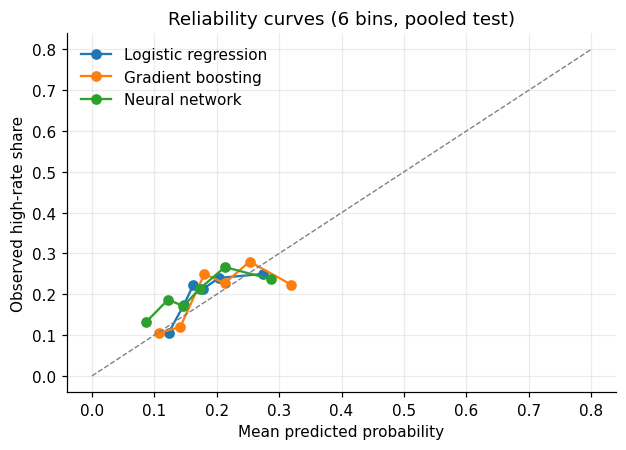

In [13]:
def calib_stats(y, p):
    lo = np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
    m = sm.Logit(y, sm.add_constant(lo)).fit(disp=0)
    return float(m.params[0]), float(m.params[1])
rows = []
for n, c in MODELS.items():
    a, b_ = calib_stats(y_t, test[c].to_numpy())
    rows.append({"model": n, "mean predicted": round(test[c].mean(), 3), "observed rate": round(y_t.mean(), 3),
                 "calibration intercept": round(a, 3), "calibration slope": round(b_, 3),
                 "log loss": round(log_loss(y_t, np.clip(test[c], 1e-6, 1 - 1e-6)), 3)})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(5.8, 4.2))
for n, c in MODELS.items():
    bins = pd.qcut(test[c], 6, duplicates="drop")
    cal = test.groupby(bins, observed=True).agg(p=(c, "mean"), o=("y", "mean"))
    ax.plot(cal.p, cal.o, "o-", label=n)
ax.plot([0, 0.8], [0, 0.8], color="gray", ls="--", lw=0.9); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed high-rate share")
ax.set_title("Reliability curves (6 bins, pooled test)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 6.2 Decision-curve analysis
Statistical metrics do not say whether acting on a model *helps*. **Net benefit** does: at a threshold probability *t* (the probability above which outreach is worth
doing, which encodes how much a wasted call costs relative to a missed facility), `net benefit = true positives/n - false positives/n x t/(1-t)`.
A model is useful at *t* only if its curve is above both "contact everyone" and "contact no one".

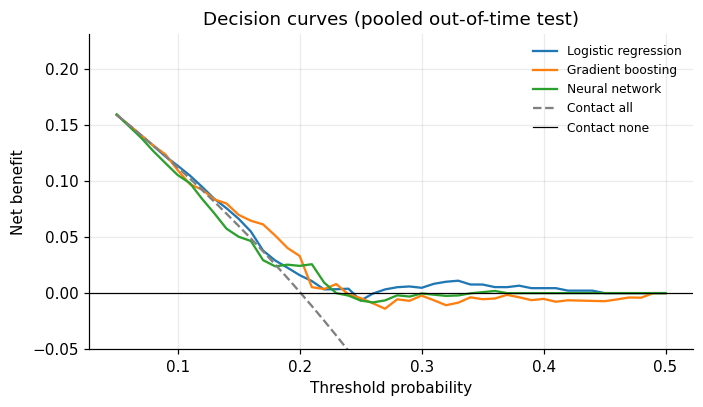

At a 20% threshold (a missed high-rate facility is worth four wasted calls):
  Logistic regression  net benefit 0.016 vs contact-all 0.001 -> about 15 extra true positives per
      1,000 facility-quarters, net of false-alarm cost
  Gradient boosting    net benefit 0.033 vs contact-all 0.001 -> about 32 extra true positives per
      1,000 facility-quarters, net of false-alarm cost
  Neural network       net benefit 0.024 vs contact-all 0.001 -> about 23 extra true positives per
      1,000 facility-quarters, net of false-alarm cost


In [14]:
thr = np.arange(0.05, 0.51, 0.01)
def net_benefit(y, p, t):
    flag = p >= t; n = len(y)
    return ((flag & (y == 1)).sum() - (flag & (y == 0)).sum() * t / (1 - t)) / n
nb_models = {n: [net_benefit(y_t, test[c].to_numpy(), t) for t in thr] for n, c in MODELS.items()}
nb_all = [y_t.mean() - (1 - y_t.mean()) * t / (1 - t) for t in thr]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for n, v in nb_models.items(): ax.plot(thr, v, label=n)
ax.plot(thr, nb_all, color="gray", ls="--", label="Contact all"); ax.axhline(0, color="k", lw=0.8, label="Contact none")
ax.set_ylim(-0.05, y_t.mean() + 0.03); ax.set_xlabel("Threshold probability"); ax.set_ylabel("Net benefit"); ax.set_title("Decision curves (pooled out-of-time test)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
t0 = 0.20
print(f"At a 20% threshold (a missed high-rate facility is worth four wasted calls):")
for n, c in MODELS.items():
    nbm = net_benefit(y_t, test[c].to_numpy(), t0); nba = y_t.mean() - (1 - y_t.mean()) * t0 / (1 - t0)
    print(f"  {n:20s} net benefit {nbm:.3f} vs contact-all {nba:.3f} -> about {1000 * (nbm - max(nba, 0)):.0f} extra true positives per 1,000 facility-quarters, net of false-alarm cost")

### 6.3 The practical question: a fixed outreach budget
If staff can contact 15% of facilities each quarter, how many of the contacted facilities are truly high-rate? **Precision@K** and **lift** (precision divided
by prevalence) answer that directly. The last column uses the ground truth (simulation only): the average *true* latent risk of the facilities chosen.

In [15]:
OUTREACH_FRACTION = 0.15
def topk_stats(score_col):
    sel_idx = []
    for q_, g_ in test.groupby("origin"):
        k = int(round(OUTREACH_FRACTION * len(g_))); sel_idx.extend(g_.sort_values(score_col, ascending=False).index[:k])
    sel = test.loc[sel_idx]
    return sel
rows = []
base_true = np.exp(test.true_log_effect - mu_te).mean()
for n, c in ALL_SCORES.items():
    sel = topk_stats(c)
    rows.append({"ranking": n, "contacted": len(sel), "precision@K": round(sel.y.mean(), 3), "lift vs prevalence": round(sel.y.mean() / y_t.mean(), 2),
                 "recall of high-rate": round(sel.y.sum() / y_t.sum(), 3), "mean true risk (x average)": round(np.exp(sel.true_log_effect - mu_te).mean(), 2)})
topk_tbl = pd.DataFrame(rows)
display(topk_tbl)
print(f"Prevalence {y_t.mean():.3f} | average true risk of all facilities {base_true:.2f} | K = {int(OUTREACH_FRACTION * 100)}% of facilities per origin")

,ranking,contacted,precision@K,lift vs prevalence,recall of high-rate,mean true risk (x average)
0,Logistic regression,68,0.324,1.61,0.242,1.47
1,Gradient boosting,68,0.250,1.24,0.187,1.39
2,Neural network,68,0.294,1.46,0.220,1.45
3,Last-quarter ratio,68,0.235,1.17,0.176,1.35
4,Cumulative ratio,68,0.353,1.76,0.264,1.53


Prevalence 0.201 | average true risk of all facilities 1.07 | K = 15% of facilities per origin


## 7. Explainability: why was a facility flagged?
Public health users will not act on a score they cannot interrogate. We use four lenses and look for agreement:
1. **SHAP values** for gradient boosting (each feature's contribution, in log-odds, to each facility's score).
2. **Partial dependence** (average predicted risk as one feature varies).
3. **Standardized coefficients** of the logistic regression.
4. **Permutation importance** for the neural network (how much AUROC falls when a feature is shuffled).

Explanations here describe the **final models trained on all labeled origins (1 to 7)** and are computed on origin 8, the *forward-looking*
list for the unobserved next quarter. Note that explanations describe what the model uses, not causes: a feature that predicts high rates is
not necessarily a thing to intervene on.

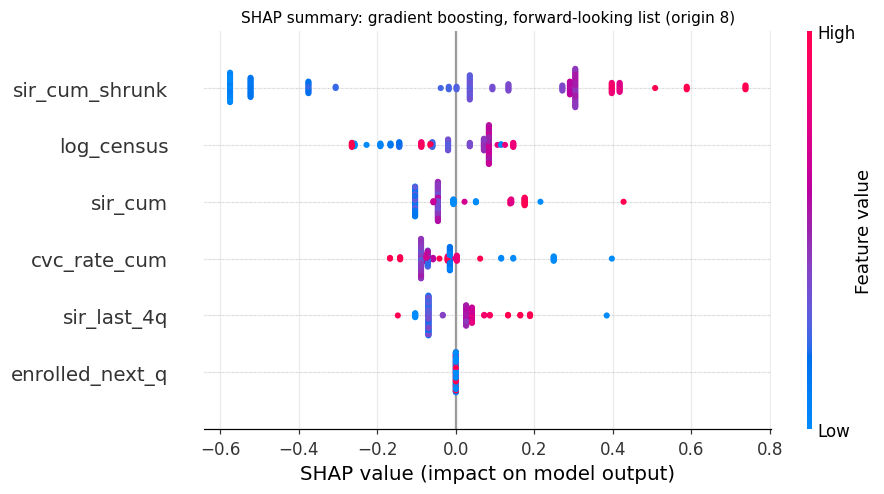

,mean |SHAP| (log-odds)
sir_cum_shrunk,0.341
log_census,0.099
sir_cum,0.082
cvc_rate_cum,0.074
sir_last_4q,0.064
enrolled_next_q,0.000


In [16]:
final_tr = ds[ds.origin <= 7]
nxt = rows_at(NQ, with_label=False)                       # features at the end of Q8: predicting Q9
nxt["size_group"] = nxt.facility_id.map(pd.qcut(fac.set_index("facility_id").mean_census, 3, labels=["Small", "Medium", "Large"]))
f_lr, f_gb, f_nn = fit_lr(final_tr, best_lr), fit_gb(final_tr, best_gb), fit_nn(final_tr, best_nn)
nxt["p_lr"], nxt["p_gb"], nxt["p_nn"] = predict_sk(f_lr, nxt), predict_sk(f_gb, nxt), predict_nn(f_nn, nxt)

pre_gb, gb_model = f_gb
X_nxt = pre_gb.transform(nxt)
explainer = shap.TreeExplainer(gb_model)
sv = np.asarray(explainer.shap_values(X_nxt))
base_val = float(np.ravel(explainer.expected_value)[0])

fig = plt.figure(figsize=(8.5, 4.6))
shap.summary_plot(sv, X_nxt, max_display=12, show=False, plot_size=None)
plt.title("SHAP summary: gradient boosting, forward-looking list (origin 8)", fontsize=10)
plt.tight_layout(); plt.show()

mean_abs = pd.Series(np.abs(sv).mean(0), index=X_nxt.columns).sort_values(ascending=False)
display(mean_abs.head(10).round(3).rename("mean |SHAP| (log-odds)").to_frame())

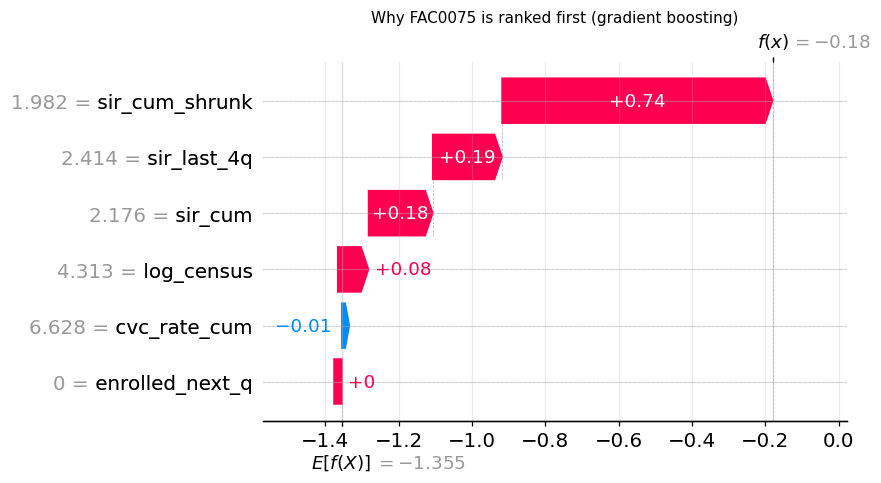

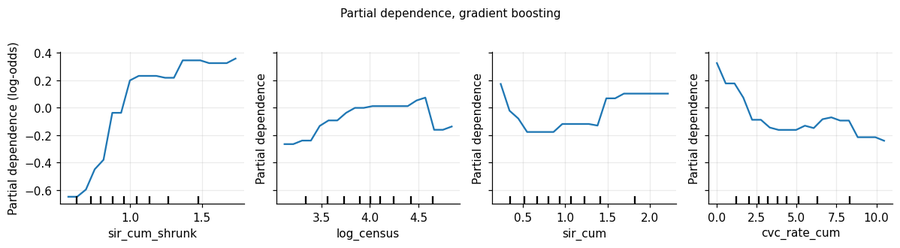

In [17]:
# Waterfall for the highest-scoring facility
top_i = int(np.argmax(nxt.p_gb.to_numpy()))
try:
    expl = shap.Explanation(values=sv[top_i], base_values=base_val, data=X_nxt.iloc[top_i].to_numpy(), feature_names=list(X_nxt.columns))
    shap.plots.waterfall(expl, max_display=10, show=False)
    plt.title(f"Why {nxt.facility_id.iloc[top_i]} is ranked first (gradient boosting)", fontsize=10); plt.tight_layout(); plt.show()
except Exception as exc:
    print("Waterfall plot unavailable in this SHAP version:", exc)

# partial dependence for the four most important raw-unit features
top_feats = [f for f in mean_abs.index if f in NUM][:4]
fig, ax = plt.subplots(1, 4, figsize=(11, 2.9), sharey=True)
PartialDependenceDisplay.from_estimator(gb_model, pre_gb.transform(final_tr), top_feats, kind="average", ax=ax, grid_resolution=20)
ax[0].set_ylabel("Partial dependence (log-odds)")
plt.suptitle("Partial dependence, gradient boosting", y=1.02, fontsize=10); plt.tight_layout(); plt.show()

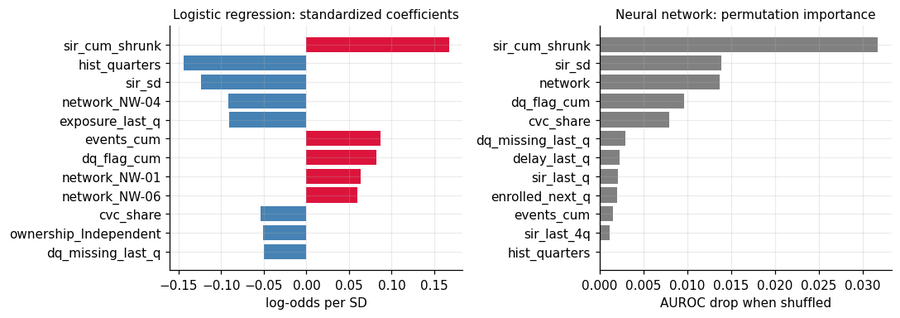

Enrollment in the collaborative: mean |SHAP| = 0.000; (in the logistic regression, standardized
    coefficient = -0.017). The program cuts CVC events by 30% in enrolled facilities, but with this
    little data that effect is easy to miss.


,SHAP (gradient boosting),LR |coefficient|,NN permutation
0,sir_cum_shrunk,sir_cum_shrunk,sir_cum_shrunk
1,log_census,hist_quarters,sir_sd
2,sir_cum,sir_sd,network
3,cvc_rate_cum,network_NW-04,dq_flag_cum
4,sir_last_4q,exposure_last_q,cvc_share


In [18]:
# Logistic regression coefficients and neural network permutation importance (on the most recent labeled origin, a pure out-of-time check)
pre_lr, lr_model = f_lr
coef = pd.Series(lr_model.coef_[0], index=pre_lr.get_feature_names_out()).sort_values(key=np.abs, ascending=False)
last_lab = ds[ds.origin == 7]
nn6 = fit_nn(ds[ds.origin <= 6], best_nn); base_auc = roc_auc_score(last_lab.y, predict_nn(nn6, last_lab))
perm_drop = {}
for f in NUM + CAT:
    drops = []
    for r_ in range(10):
        sh = last_lab.copy(); sh[f] = sh[f].sample(frac=1, random_state=r_).to_numpy()
        drops.append(base_auc - roc_auc_score(last_lab.y, predict_nn(nn6, sh)))
    perm_drop[f] = np.mean(drops)
perm = pd.Series(perm_drop).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
c12 = coef.head(12)[::-1]; ax[0].barh(c12.index, c12.values, color=np.where(c12.values > 0, "crimson", "steelblue"))
ax[0].set_title("Logistic regression: standardized coefficients", fontsize=10); ax[0].set_xlabel("log-odds per SD")
p12 = perm.head(12)[::-1]; ax[1].barh(p12.index, p12.values, color="gray"); ax[1].set_title("Neural network: permutation importance", fontsize=10); ax[1].set_xlabel("AUROC drop when shuffled")
plt.tight_layout(); plt.show()

if "enrolled_next_q" in mean_abs.index:
    print(f"Enrollment in the collaborative: mean |SHAP| = {mean_abs['enrolled_next_q']:.3f}; (in the logistic regression, standardized coefficient = "
          f"{coef.get('enrolled_next_q', float('nan')):+.3f}). The program cuts CVC events by 30% in enrolled facilities, but with this little data that effect is easy to miss.")
top5 = pd.DataFrame({"SHAP (gradient boosting)": mean_abs.head(5).index.tolist(), "LR |coefficient|": coef.head(5).index.tolist(), "NN permutation": perm.head(5).index.tolist()})
display(top5)

**Reading the explanation lenses.** All three views agree on the main driver: the credibility-weighted cumulative ratio (`sir_cum_shrunk`) leads the SHAP ranking, the logistic regression, and the neural network's permutation importance. Beyond that, agreement is only partial, which is itself informative. Two things to notice. First, the **enrollment flag has no importance**: the 30% CVC reduction in the collaborative is too small a signal for this little data, so the models ignore a program the analysts know exists. Second, the logistic regression and the neural network both give weight to the **network indicators**, although networks have no true effect (notebook 02). That is a sign of noise-fitting in the weaker models, and a reason to prefer a short, domain-driven feature list when data are scarce.

### 7.1 Plain-language reason codes
The ranking is turned into something an outreach worker can read: for each facility, the three features that pushed its score up the most, with their values.

In [19]:
FRIENDLY = {"sir_cum": "cumulative ratio vs expected", "sir_cum_shrunk": "credibility-weighted ratio vs expected", "sir_last_4q": "ratio vs expected, last 4 quarters",
            "sir_last_2q": "ratio vs expected, last 2 quarters", "sir_last_q": "ratio vs expected, last quarter", "sir_trend": "change in ratio from prior quarter",
            "sir_sd": "quarter-to-quarter volatility", "events_cum": "total events to date", "events_last_q": "events last quarter", "events_last_2q": "events, last 2 quarters",
            "cvc_rate_last_q": "CVC event rate last quarter", "cvc_rate_cum": "CVC event rate to date", "cvc_events_cum": "CVC events to date", "cvc_share": "share of patients with a CVC",
            "avf_share": "share of patients with a fistula", "log_census": "facility size (log patients)", "exposure_last_q": "expected events last quarter",
            "dq_flag_last_q": "flagged submissions last quarter", "dq_flag_cum": "flagged submissions to date", "dq_missing_last_q": "missing months last quarter",
            "delay_last_q": "reporting delay (days)", "invalid_share_last_q": "share of invalid events", "enrolled_next_q": "enrolled in the collaborative", "hist_quarters": "years of history"}
def friendly(name): return FRIENDLY.get(name, name.replace("_", " "))
def reasons_from(contrib, Xdf, k=3):
    out = []
    for i in range(len(Xdf)):
        order = np.argsort(-contrib[i])[:k]
        out.append("; ".join(f"{friendly(Xdf.columns[j])} = {Xdf.iloc[i, j]:.2f}" for j in order if contrib[i, j] > 0) or "no strong upward drivers")
    return out
nxt["reasons_gb"] = reasons_from(sv, X_nxt)
lr_contrib = (pre_lr.transform(nxt).to_numpy() - pre_lr.transform(final_tr).to_numpy().mean(0)) * lr_model.coef_[0]
nxt["reasons_lr"] = reasons_from(lr_contrib, pre_lr.transform(nxt).assign(**{c: nxt[c].to_numpy() for c in NUM}))   # show raw values in the text
# agreement between the two explanations for the facilities both models rank highest
top_gb = set(nxt.nlargest(24, "p_gb").facility_id); top_lr = set(nxt.nlargest(24, "p_lr").facility_id)
print(f"Overlap of the top-24 lists (GB vs LR): {len(top_gb & top_lr)} of 24 | rank correlation of probabilities (Spearman): {stats.spearmanr(nxt.p_gb, nxt.p_lr)[0]:.2f}")

Overlap of the top-24 lists (GB vs LR): 17 of 24 | rank correlation of probabilities (Spearman):
    0.79


## 8. Fairness audit: does the model systematically under-flag some facilities?
We audit by **facility size** (terciles of census), **ownership**, and **urban/rural**. Two different yardsticks, because they can disagree:

- **Against the observed label** (a noisy count, so smaller facilities can rarely reach "3 or more events and 1.5x expected" even when their risk is high):
  AUROC, selection rate, true-positive rate (TPR), precision.
- **Against true latent risk** (ground truth, simulation only): of the facilities that are **truly** high-risk (at least 1.3x average), what share does the
  model put on the call list? This separates "the model under-flags small facilities" from "the outcome is harder to observe in small facilities".

The list is the top 15% per origin. Gaps are reported with facility-level bootstrap intervals.

In [20]:
print(f"Fairness audit of the model selected in section 5.1: {chosen_name}")
def flag_top(df, col, frac=OUTREACH_FRACTION):
    f = pd.Series(False, index=df.index)
    for q_, g_ in df.groupby("origin"):
        k = int(round(frac * len(g_))); f.loc[g_.sort_values(col, ascending=False).index[:k]] = True
    return f

def audit(df, col, groups=("size_group", "ownership", "urban_rural")):
    d = df.copy(); d["flag"] = flag_top(d, col)
    rows = []
    for gv in groups:
        for lvl, g_ in d.groupby(gv):
            hi_label, hi_true = g_.y == 1, g_.true_high == 1
            rows.append({"group": f"{gv}: {lvl}", "n": len(g_), "prevalence": g_.y.mean(),
                         "AUROC": roc_auc_score(g_.y, g_[col]) if g_.y.nunique() > 1 else np.nan,
                         "selected": g_.flag.mean(), "TPR vs label": g_.loc[hi_label, "flag"].mean() if hi_label.any() else np.nan,
                         "precision": g_.loc[g_.flag, "y"].mean() if g_.flag.any() else np.nan,
                         "TPR vs true risk": g_.loc[hi_true, "flag"].mean() if hi_true.any() else np.nan,
                         "mean predicted": g_[col].mean()})
    return pd.DataFrame(rows)

aud = audit(test, CHOSEN)
display(aud.round(3))

Fairness audit of the model selected in section 5.1: Logistic regression


,group,n,prevalence,AUROC,selected,TPR vs label,precision,TPR vs true risk,mean predicted
0,size_group: Small,145,0.179,0.461,0.186,0.269,0.259,0.345,0.187
1,size_group: Medium,153,0.170,0.548,0.170,0.192,0.192,0.394,0.181
2,size_group: Large,155,0.252,0.691,0.097,0.256,0.667,0.375,0.177
3,ownership: Independent,68,0.103,0.534,0.103,0.143,0.143,0.222,0.168
4,ownership: Large_chain,287,0.206,0.614,0.139,0.254,0.375,0.396,0.181
5,ownership: Nonprofit,98,0.255,0.483,0.214,0.240,0.286,0.435,0.193
6,urban_rural: Rural,100,0.230,0.552,0.200,0.391,0.450,0.423,0.193
7,urban_rural: Urban,353,0.193,0.578,0.136,0.191,0.271,0.353,0.178


,comparison,metric,gap,95% CI,CI excludes 0
0,Small minus Large,selected,0.089,-0.011 to +0.202,False
1,Small minus Large,TPR label,0.013,-0.221 to +0.279,False
2,Small minus Large,TPR true risk,-0.030,-0.379 to +0.267,False
3,Rural minus Urban,selected,0.064,-0.039 to +0.180,False
4,Rural minus Urban,TPR label,0.200,-0.031 to +0.433,False
5,Rural minus Urban,TPR true risk,0.070,-0.188 to +0.342,False
6,Independent minus Large_chain,selected,-0.036,-0.123 to +0.068,False
7,Independent minus Large_chain,TPR label,-0.111,-0.354 to +0.269,False
8,Independent minus Large_chain,TPR true risk,-0.174,-0.456 to +0.106,False


0 of 9 gap intervals exclude zero. With nine comparisons at 95%, about 0.5 would be expected to do
    so by chance alone, so a single exclusion is a prompt to look closer (is it consistent across
    the three metrics, is the group large enough, is the direction plausible?), not proof of
    unfairness. In this simulation ownership has no true effect on risk.


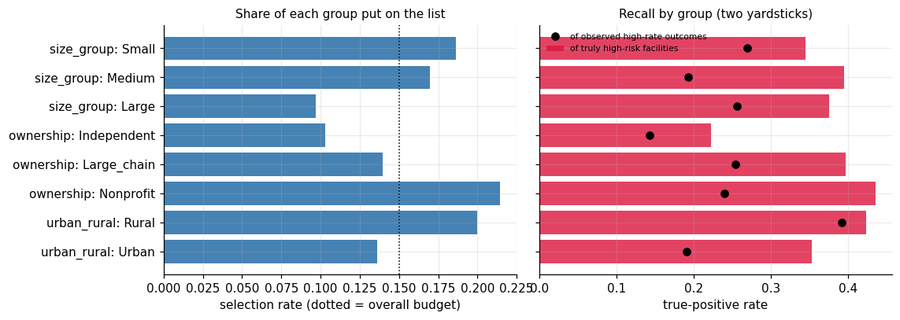

In [21]:
def gap_boot(df, col, gv, lvl_a, lvl_b, metric, B=1000):
    d = df.copy(); d["flag"] = flag_top(d, col)
    pos = {f: np.flatnonzero((d.facility_id == f).to_numpy()) for f in fac_ids}
    def stat(sub):
        out = []
        for lvl in (lvl_a, lvl_b):
            g_ = sub[sub[gv] == lvl]
            if metric == "selected": out.append(g_.flag.mean())
            elif metric == "TPR label": out.append(g_.loc[g_.y == 1, "flag"].mean())
            else: out.append(g_.loc[g_.true_high == 1, "flag"].mean())
        return out[0] - out[1]
    vals = np.array([stat(d.iloc[np.concatenate([pos[f] for f in rng2.choice(fac_ids, len(fac_ids))])]) for _ in range(B)])
    return stat(d), np.nanpercentile(vals, 2.5), np.nanpercentile(vals, 97.5)

def gap_table(col):
    rows = []
    for gv, a, b_ in [("size_group", "Small", "Large"), ("urban_rural", "Rural", "Urban"), ("ownership", "Independent", "Large_chain")]:
        for metric in ("selected", "TPR label", "TPR true risk"):
            est, lo_, hi_ = gap_boot(test, col, gv, a, b_, metric, B=500)
            rows.append({"comparison": f"{a} minus {b_}", "metric": metric, "gap": round(est, 3), "95% CI": f"{lo_:+.3f} to {hi_:+.3f}",
                         "CI excludes 0": bool(lo_ > 0 or hi_ < 0)})
    return pd.DataFrame(rows)
gaps = gap_table(CHOSEN)
display(gaps)
n_sig = int(gaps["CI excludes 0"].sum())
print(f"{n_sig} of {len(gaps)} gap intervals exclude zero. With nine comparisons at 95%, about {0.05 * len(gaps):.1f} would be expected to do so by chance alone, so a single exclusion is a prompt to "
      "look closer (is it consistent across the three metrics, is the group large enough, is the direction plausible?), not proof of unfairness. In this simulation ownership has no true effect on risk.")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
a_ = aud.set_index("group")
ax[0].barh(a_.index[::-1], a_["selected"][::-1], color="steelblue"); ax[0].axvline(OUTREACH_FRACTION, color="k", ls=":", lw=1)
ax[0].set_title("Share of each group put on the list", fontsize=10); ax[0].set_xlabel("selection rate (dotted = overall budget)")
ax[1].barh(a_.index[::-1], a_["TPR vs true risk"][::-1], color="crimson", alpha=0.8, label="of truly high-risk facilities")
ax[1].plot(a_["TPR vs label"][::-1], a_.index[::-1], "ko", label="of observed high-rate outcomes"); ax[1].legend(frameon=False, fontsize=7)
ax[1].set_title("Recall by group (two yardsticks)", fontsize=10); ax[1].set_xlabel("true-positive rate")
plt.tight_layout(); plt.show()

### 8.1 A mitigation experiment: stratified selection
If small facilities are under-selected, one remedy within a fixed budget is to **select the top 15% inside each size group** instead of overall.
The trade-off is what it costs in overall precision. We report the effect on both yardsticks so the choice is transparent, not assumed.

In [22]:
def stratified_flag(df, col, by="size_group", frac=OUTREACH_FRACTION):
    f = pd.Series(False, index=df.index)
    for (q_, lvl), g_ in df.groupby(["origin", by]):
        k = max(1, int(round(frac * len(g_)))); f.loc[g_.sort_values(col, ascending=False).index[:k]] = True
    return f
rows = []
for lab, flag in [("Overall top 15%", flag_top(test, CHOSEN)), ("Top 15% within each size group", stratified_flag(test, CHOSEN))]:
    d = test.assign(flag=flag)
    row = {"selection rule": lab, "list size": int(flag.sum()), "precision": round(d.loc[d.flag, "y"].mean(), 3),
           "TPR vs true risk (all)": round(d.loc[d.true_high == 1, "flag"].mean(), 3)}
    for g in ("Small", "Medium", "Large"):
        row[f"TPR true risk: {g}"] = round(d.loc[(d.size_group == g) & (d.true_high == 1), "flag"].mean(), 3)
    rows.append(row)
mit = pd.DataFrame(rows)
display(mit)
d_small = mit.iloc[1]["TPR true risk: Small"] - mit.iloc[0]["TPR true risk: Small"]
print(f"Effect of stratified selection on the recall of truly high-risk SMALL facilities: {d_small:+.3f}; on overall precision: {mit.iloc[1]['precision'] - mit.iloc[0]['precision']:+.3f}. "
      "Equalizing how many facilities are picked per group is not the same as equalizing how well each group's risk is detected: if the underlying score is "
      "less informative for small facilities (sparse data), parity in selection counts may not close the detection gap.")

,selection rule,list size,precision,TPR vs true risk (all),TPR true risk: Small,TPR true risk: Medium,TPR true risk: Large
0,Overall top 15%,68,0.324,0.372,0.345,0.394,0.375
1,Top 15% within each size group,70,0.314,0.415,0.276,0.364,0.594


Effect of stratified selection on the recall of truly high-risk SMALL facilities: -0.069; on overall
    precision: -0.010. Equalizing how many facilities are picked per group is not the same as
    equalizing how well each group's risk is detected: if the underlying score is less informative
    for small facilities (sparse data), parity in selection counts may not close the detection gap.


## 9. A negative control: a target with no signal to find
Data-quality problems in this simulation (late, missing, mismatched submissions) were injected **independently** in every month, so a facility's past errors say
nothing about its future errors. That makes "poor data quality next quarter" a deliberately unpredictable target. A trustworthy pipeline should find **AUROC near
0.5** here. If it reported something impressive, that would signal leakage or overfitting. (Real reporting problems usually *do* persist, for example through staff
turnover or software, so on real data this target is expected to be predictable; this check tests the pipeline, not the world.)

In [23]:
rows, store = [], []
for q in TEST_ORIGINS:
    tr, te = ds[ds.origin < q], ds[ds.origin == q].copy()
    te["p_lr"] = predict_sk(fit_lr(tr, best_lr, "y_dq"), te); te["p_gb"] = predict_sk(fit_gb(tr, best_gb, "y_dq"), te); store.append(te)
dq_t = pd.concat(store, ignore_index=True)
yd = dq_t.y_dq.to_numpy()
fpos = {f: np.flatnonzero((dq_t.facility_id == f).to_numpy()) for f in fac_ids}
bi = [np.concatenate([fpos[f] for f in rng2.choice(fac_ids, len(fac_ids))]) for _ in range(500)]
for n, c in [("Logistic regression", "p_lr"), ("Gradient boosting", "p_gb")]:
    a = np.array([roc_auc_score(yd[i], dq_t[c].to_numpy()[i]) for i in bi])
    rows.append({"model": n, "AUROC (95% CI)": f"{roc_auc_score(yd, dq_t[c]):.3f} ({np.percentile(a, 2.5):.3f} to {np.percentile(a, 97.5):.3f})", "contains 0.5": bool(np.percentile(a, 2.5) <= 0.5 <= np.percentile(a, 97.5))})
display(pd.DataFrame(rows))
lag = pd.DataFrame({"last": DQ_BAD[:, 1:7].ravel(), "next": DQ_BAD[:, 2:8].ravel()})
print(f"Share of facility-quarters with a data-quality problem: {yd.mean():.3f} | correlation between a facility's problem this quarter and next quarter: {lag.corr().iloc[0, 1]:+.3f} (about 0 means no persistence, so nothing to learn)")

,model,AUROC (95% CI),contains 0.5
0,Logistic regression,0.487 (0.428 to 0.548),True
1,Gradient boosting,0.503 (0.440 to 0.569),True


Share of facility-quarters with a data-quality problem: 0.245 | correlation between a facility's
    problem this quarter and next quarter: +0.049 (about 0 means no persistence, so nothing to
    learn)


## 10. The outreach list for the next, unobserved quarter (Q9)
The model chosen by the rule in section 5.1 produces the list. Reason codes come from that model (the neural network falls back to gradient boosting for reasons).

In [24]:
print(f"Model used for the list: {chosen_name}")
nxt["p_chosen"] = nxt[col]
nxt["rank"] = nxt.p_chosen.rank(ascending=False, method="first").astype(int)
K_LIST = int(round(OUTREACH_FRACTION * len(nxt)))
outreach = (nxt.sort_values("rank").head(K_LIST)[["rank", "facility_id", "p_chosen", "size_group", "ownership", "urban_rural", reason_col]]
            .rename(columns={reason_col: "top drivers", "p_chosen": "probability high next quarter"}))
outreach["probability high next quarter"] = outreach["probability high next quarter"].round(3)
display(outreach.drop(columns="top drivers").head(10).reset_index(drop=True))
print("Top drivers for the five highest-ranked facilities:")
for _, r_ in outreach.head(5).iterrows():
    print(f"  #{int(r_['rank'])} {r_['facility_id']}: {r_['top drivers']}")
print(f"List size: {K_LIST} facilities (15% budget). Size mix on the list: {outreach.size_group.value_counts().to_dict()}")

Model used for the list: Logistic regression


,rank,facility_id,probability high next quarter,size_group,ownership,urban_rural
0,1,FAC0013,0.520,Large,Large_chain,Urban
1,2,FAC0134,0.490,Large,Nonprofit,Urban
2,3,FAC0075,0.435,Large,Large_chain,Urban
3,4,FAC0096,0.432,Large,Large_chain,Urban
4,5,FAC0051,0.334,Small,Large_chain,Rural
5,6,FAC0143,0.333,Medium,Nonprofit,Rural
6,7,FAC0127,0.313,Medium,Large_chain,Urban
7,8,FAC0035,0.310,Medium,Large_chain,Urban
8,9,FAC0027,0.299,Small,Large_chain,Urban
9,10,FAC0009,0.293,Large,Large_chain,Urban


Top drivers for the five highest-ranked facilities:
  #1 FAC0013: credibility-weighted ratio vs expected = 2.25; total events to date = 64.00; CVC
      events to date = 30.00
  #2 FAC0134: total events to date = 86.00; credibility-weighted ratio vs expected = 1.91; CVC
      events to date = 46.00
  #3 FAC0075: credibility-weighted ratio vs expected = 1.98; total events to date = 55.00; flagged
      submissions to date = 3.00
  #4 FAC0096: total events to date = 97.00; credibility-weighted ratio vs expected = 1.79; CVC
      events to date = 55.00
  #5 FAC0051: credibility-weighted ratio vs expected = 2.15; flagged submissions to date = 4.00;
      cumulative ratio vs expected = 2.80
List size: 24 facilities (15% budget). Size mix on the list: {'Large': 11, 'Medium': 8, 'Small': 5}


In [25]:
test_out = test[["facility_id", "origin", "y", "true_high", "size_group", "ownership", "urban_rural", "p_lr", "p_gb", "p_nn", "sir_last_q", "sir_cum"]].copy()
test_out.to_csv(f"{OUT}/out_of_time_predictions.csv", index=False)
outreach.to_csv(f"{OUT}/outreach_list_next_quarter.csv", index=False)
nxt[["facility_id", "p_lr", "p_gb", "p_nn", "p_chosen", "rank", "reasons_gb", "reasons_lr"]].to_csv(f"{OUT}/all_facilities_next_quarter_scores.csv", index=False)
with pd.ExcelWriter(f"{OUT}/outreach_model_report.xlsx", engine="openpyxl") as xw:
    prev.reset_index().to_excel(xw, sheet_name="Prevalence by origin", index=False)
    base.reset_index().to_excel(xw, sheet_name="Baselines and ceiling", index=False)
    lr_cv.to_excel(xw, sheet_name="LR tuning", index=False); gb_cv.to_excel(xw, sheet_name="GB tuning", index=False)
    res_tbl.to_excel(xw, sheet_name="Test metrics", index=False); pd.DataFrame(dr).to_excel(xw, sheet_name="Paired differences", index=False)
    pd.DataFrame(rows).to_excel(xw, sheet_name="Negative control", index=False)
    topk_tbl.to_excel(xw, sheet_name="Top-K lists", index=False)
    aud.to_excel(xw, sheet_name="Fairness audit", index=False); gaps.to_excel(xw, sheet_name="Fairness gaps", index=False)
    mean_abs.rename("mean_abs_shap").rename_axis("feature").reset_index().to_excel(xw, sheet_name="SHAP importance", index=False)
    outreach.to_excel(xw, sheet_name="Outreach list Q9", index=False)
    for ws in xw.book.worksheets:
        for column in ws.columns:
            ws.column_dimensions[column[0].column_letter].width = min(60, max(11, max(len(str(c.value or "")) for c in column[:40]) + 2))
        ws.freeze_panes = "A2"
print(sorted(os.listdir(OUT)))

['all_facilities_next_quarter_scores.csv', 'out_of_time_predictions.csv',
    'outreach_list_next_quarter.csv', 'outreach_model_report.xlsx']


## 11. So what for public health?
- **Know the ceiling before comparing models.** The outcome is a noisy count, so even perfect knowledge of risk cannot predict it exactly. Judging a model against
  that ceiling (and against a one-line baseline) is far more informative than its raw AUROC.
- **Simple is a feature.** On about 700 training rows, check honestly whether boosting or a neural network reliably beats a regularized logistic regression or even the
  cumulative ratio. When differences are within the bootstrap noise, the simpler, more explainable model is the right default.
- **Ranking quality is not decision value.** Calibration and decision curves answer different questions from AUROC: are the probabilities believable, and does acting on the
  list beat contacting everyone or no one at the program's own cost trade-off?
- **Explanations need agreement.** When SHAP, coefficients, and permutation importance point to the same few drivers, the explanation is credible. Reason codes make the list
  usable by outreach staff, but they describe the model, not causes.
- **Fairness has two yardsticks.** Measured against the noisy label, small facilities can look under-flagged simply because their events are rarer and harder to observe. Measured
  against true risk, the picture can differ. Audit both, report intervals, and test a mitigation before adopting it.
- **A negative control protects against fooling yourself.** A pipeline that cannot return AUROC near 0.5 on a target with no signal should not be trusted on one with signal.

## Limitations
- Synthetic data with a simple risk structure: persistent facility risk plus Poisson-like noise. Real risk drifts, depends on staffing, case mix, and policy, and is correlated with reporting quality.
- Data-quality errors are independent by construction (hence the negative control). Real reporting problems persist, so that target would behave very differently.
- Only about 700 training rows and three test origins; intervals are wide and one simulated dataset (seed 42) is all we have. Treat model rankings as illustrative.
- The 1.5x-and-3-events outcome and the 15% budget are analyst choices. Different definitions change prevalence and which model looks best.
- Hyperparameter search was small and fixed in advance (the neural network was tuned only on its number of epochs), so its result should not be read as a general verdict on neural networks for tabular data.
- Fairness is audited on three attributes only, with ground-truth risk as the yardstick, which no real program has. In practice the second yardstick would be an external benchmark or clinical review.

## Next notebooks
`03b` early-warning charts (CUSUM/EWMA), cluster detection, and forecasting | `05` inquiry triage, facility report generator, training materials, and the dialysis safety webpage text.